# Tutorial: Ward Map and Collision Locations in Colab
### MIS Data Analytics Case Competition — City of Norman

In this tutorial you will learn two skills you need for the case:

**Part A — Load the City Council ward map (GeoJSON)** and draw it.

**Part B — Get a good location (latitude/longitude) for every collision**, using intersection coordinates:
1. find crashes whose coordinates are missing,
2. fill them in from other crashes at the same intersection,
3. move "From" crashes the right number of feet away from the intersection.

Everything uses tools you already know: `pandas`, `if/elif`, simple functions, dictionaries, and loops.

> **Before you start:** put these two files in your group's shared Google Drive folder:
> * `Council_Wards_4934068591990916100.geojson`
> * `Traffic_Project_OU_FALL_PROJECT.xlsx`

---
## Step 0 — Connect Colab to Google Drive

Colab cannot see your Drive until you **mount** it. Run the cell below and click **Connect to Google Drive** when asked.

If the shared folder was created by a teammate, it is in **Shared with me**. Right-click the folder in Google
Drive → **Organize → Add shortcut** → **My Drive**. Then it appears under `MyDrive`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Now tell Python where your files are. **Change the folder name** to your group's folder.
To find the exact path: click the 📁 icon on the left of Colab → `drive` → `MyDrive` → your folder →
right-click a file → **Copy path**.

In [ ]:
DATA_FOLDER = '/content/drive/MyDrive/Colab Notebooks/MIS3213/Norman_Traffic_Analysis/data/'

WARD_FILE = DATA_FOLDER + 'Council_Wards_4934068591990916100.geojson'
COLLISION_FILE = DATA_FOLDER + 'Traffic_Project_OU_FALL_PROJECT.xlsx'

import os
print('Ward file found?     ', os.path.exists(WARD_FILE))
print('Collision file found?', os.path.exists(COLLISION_FILE))

Ward file found?      True
Collision file found? True


Both lines should say `True`. If one says `False`, check the folder name and spelling (capital letters matter).

---
# Part A — The Ward Map (GeoJSON)

## A1. What is a GeoJSON file?

A **GeoJSON** file is a text file that stores **shapes on a map**. Our file has one shape (a *polygon*) for each of
Norman's **8 City Council wards**. Each shape has:
* **properties** — normal data columns, like the ward number, and
* **geometry** — the list of latitude/longitude points that draw the outline.

We read it with **geopandas**. A geopandas table (a *GeoDataFrame*) works just like a pandas DataFrame, but it has a
special `geometry` column. Colab already has geopandas installed.

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

wards = gpd.read_file(WARD_FILE)

print('Number of rows (wards):', len(wards))
print('Columns:', list(wards.columns))

Number of rows (wards): 8
Columns: ['OBJECTID', 'DIST_NAME', 'Ward_num', 'WARDNO', 'GlobalID', 'geometry']


## A2. Look at the table
There are many columns we do not need. The important ones are `WARDNO` (ward number), `DIST_NAME` (ward name),
and `geometry` (the shape).

In [ ]:
wards = wards[['WARDNO', 'DIST_NAME', 'geometry']]
wards

,WARDNO,DIST_NAME,geometry
0,1,Ward 1,"POLYGON ((-97.41169 35.21835, -97.41112 35.218..."
1,2,Ward 2,"POLYGON ((-97.45902 35.22791, -97.45903 35.227..."
2,3,Ward 3,"POLYGON ((-97.48481 35.19378, -97.48516 35.193..."
3,4,Ward 4,"POLYGON ((-97.43973 35.23285, -97.43898 35.232..."
4,5,Ward 5,"POLYGON ((-97.35303 35.16032, -97.35391 35.160..."
5,6,Ward 6,"POLYGON ((-97.41335 35.21836, -97.41385 35.218..."
6,7,Ward 7,"POLYGON ((-97.43291 35.20383, -97.43281 35.203..."
7,8,Ward 8,"POLYGON ((-97.48722 35.30171, -97.48705 35.301..."


## A3. Check the coordinate system (CRS)

The **CRS** tells us what the numbers in `geometry` mean. `EPSG:4326` means plain **longitude and latitude in
degrees** — the same kind of numbers as the `Lat` and `Lon` columns in the collision data. Good: they match.

In [ ]:
print(wards.crs)

EPSG:4326


## A4. Draw the ward map
`.plot()` draws every shape. We add the ward number in the middle of each ward with a simple `for` loop.

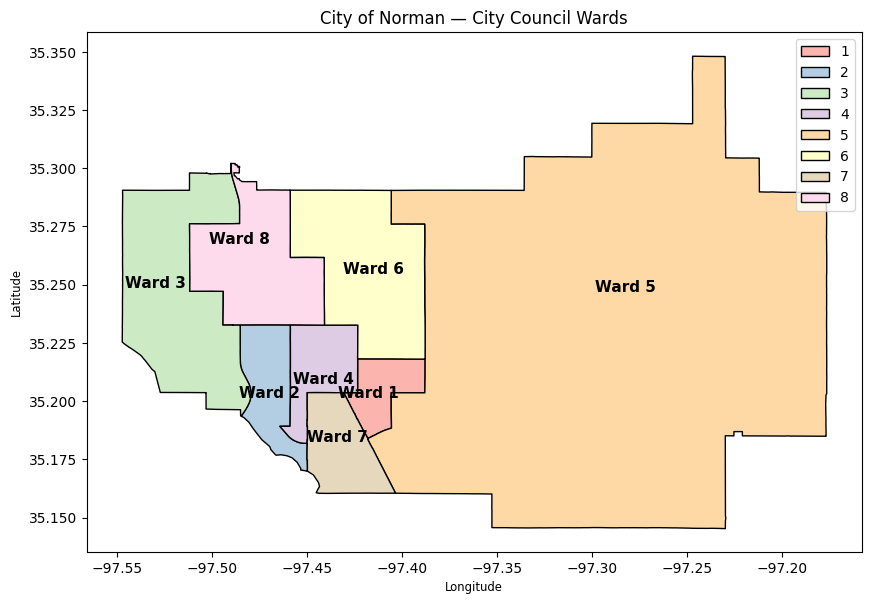

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
wards.plot(ax=ax, column='WARDNO', categorical=True, cmap='Pastel1', edgecolor='black', legend=True)

for i in range(len(wards)):
    shape = wards['geometry'].iloc[i]
    center = shape.representative_point()        # a point that is always inside the shape
    ax.text(center.x, center.y, 'Ward ' + str(wards['WARDNO'].iloc[i]), ha='center', fontsize=11, weight='bold')

ax.set_title('City of Norman — City Council Wards')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

## A5. Bonus: which ward is a point in?

A shape can tell us if it **contains** a point. We loop over the 8 wards and return the first one that contains
the point. (A point exactly on a boundary line may return no ward — we will handle boundaries in a later lab.)

In [ ]:
from shapely.geometry import Point

def find_ward(lat, lon):
    """Return the ward number that contains (lat, lon), or None."""
    p = Point(lon, lat)                 # careful: Point takes (x = longitude, y = latitude)
    for i in range(len(wards)):
        if wards['geometry'].iloc[i].contains(p):
            return wards['WARDNO'].iloc[i]
    return None

# Try it: a point on the OU campus, and a point on 12th Ave NE
print('OU campus  ->', find_ward(35.2059, -97.4457))
print('12th Ave NE ->', find_ward(35.2400, -97.4240))

OU campus  -> 4
12th Ave NE -> 6


---
# Part B — Collision Locations

## B1. Load the collision data
The workbook has several sheets. One row in **`Base_Data`** = one crash. This file is big, so loading takes about
30–60 seconds.

In [ ]:
crashes = pd.read_excel(COLLISION_FILE, sheet_name='Base_Data')
print('Rows:', len(crashes))
crashes.head()

Rows: 23595


,Year,AccidentNumber,AccidentDatetime,From_At,Direction,Distance,HouseNumber,StreetPrefix,StreetName,StreetType,StreetSuffix,XStreetPrefix,XStreetName,XStreetType,XStreetSuffix,Lat,Lon,CauseCode
0,2016,2016-00000027,2016-01-01 01:29:00,At,NaN,NaN,NaN,E,COMANCHE,ST,NaN,S,CRAWFORD,AVE,NaN,35.221158,-97.439919,-67028.0
1,2016,2016-00000192,2016-01-01 22:20:00,From,DirectionSouth,35.0,NaN,NaN,12TH,AVE,NE,E,ROCK CREEK,RD,NaN,35.247342,-97.423480,-67028.0
2,2016,2016-00000267,2016-01-02 10:34:00,From,DirectionEast,100.0,NaN,W,ROBINSON,ST,NaN,NaN,STUBBEMAN,AVE,NaN,35.232927,-97.449941,-67239.0
3,2016,2016-00000279,2016-01-02 11:38:00,At,NaN,NaN,NaN,W,ROBINSON,ST,NaN,N,INTERSTATE,DR,NaN,35.232920,-97.488371,-68519.0
4,2016,2016-00000309,2016-01-02 14:04:00,From,DirectionNorth,25.0,NaN,NaN,ALAMEDA,ST,NaN,NaN,12TH,AVE,SE,35.218387,-97.423604,-67239.0


In [ ]:
crashes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23595 entries, 0 to 23594
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Year              23595 non-null  int64         
 1   AccidentNumber    23595 non-null  object        
 2   AccidentDatetime  23595 non-null  datetime64[ns]
 3   From_At           23595 non-null  object        
 4   Direction         13894 non-null  object        
 5   Distance          13894 non-null  float64       
 6   HouseNumber       625 non-null    float64       
 7   StreetPrefix      11927 non-null  object        
 8   StreetName        23595 non-null  object        
 9   StreetType        21259 non-null  object        
 10  StreetSuffix      4386 non-null   object        
 11  XStreetPrefix     9594 non-null   object        
 12  XStreetName       20682 non-null  object        
 13  XStreetType       20629 non-null  object        
 14  XStreetSuffix     3580

In [ ]:
crashes.isnull().sum()

,0
Year,0
AccidentNumber,0
AccidentDatetime,0
From_At,0
Direction,9701
Distance,9701
HouseNumber,22970
StreetPrefix,11668
StreetName,0
StreetType,2336


## B2. Understand the location columns

| Column | Meaning |
|---|---|
| `StreetName` | the road the crash happened **on** |
| `XStreetName` | the **cross street** of the nearest intersection |
| `From_At` | `At` = at the intersection; `From` = some distance away from it |
| `Direction` | which way from the intersection (`DirectionNorth`, `South`, `East`, `West`) |
| `Distance` | how many **feet** from the intersection |
| `Lat`, `Lon` | coordinates of the **intersection**, not of the crash itself |

Read row 1 below like a sentence:
*"The crash happened on **12TH AVE NE**, **35 feet South** of **ROCK CREEK**."*
The `Lat`/`Lon` are for the intersection of 12th Ave NE and Rock Creek Rd — so we must move the point 35 feet south.

In [ ]:
location_columns = ['StreetName', 'StreetType', 'StreetSuffix', 'XStreetName', 'From_At', 'Direction', 'Distance', 'Lat', 'Lon']
crashes[location_columns].head(6)

,StreetName,StreetType,StreetSuffix,XStreetName,From_At,Direction,Distance,Lat,Lon
0,COMANCHE,ST,NaN,CRAWFORD,At,NaN,NaN,35.221158,-97.439919
1,12TH,AVE,NE,ROCK CREEK,From,DirectionSouth,35.0,35.247342,-97.423480
2,ROBINSON,ST,NaN,STUBBEMAN,From,DirectionEast,100.0,35.232927,-97.449941
3,ROBINSON,ST,NaN,INTERSTATE,At,NaN,NaN,35.232920,-97.488371
4,ALAMEDA,ST,NaN,12TH,From,DirectionNorth,25.0,35.218387,-97.423604
5,CONSTITUTION,ST,NaN,CLASSEN,From,DirectionWest,185.0,35.192661,-97.423800


In [ ]:
print(crashes['From_At'].value_counts())
print()
print(crashes['Direction'].value_counts())

From_At
From    13893
At       9702
Name: count, dtype: int64

Direction
DirectionWest     3977
DirectionEast     3437
DirectionNorth    3388
DirectionSouth    3092
Name: count, dtype: int64


More than half of the crashes are `From` crashes. If we use their `Lat`/`Lon` as-is, every one of them would be
stacked on top of an intersection.

---
## B3. Step 1 — Find the missing coordinates

Some crashes have `Lat` and `Lon` equal to **-361**. That is not a real place (latitude must be between -90 and 90).
It is the City's code for *"no coordinates."* We replace it with `NaN` (pandas' "missing" value).

In [ ]:
import numpy as np

crashes.loc[crashes['Lat'] < -90, 'Lat'] = np.nan
crashes.loc[crashes['Lon'] < -180, 'Lon'] = np.nan

missing = crashes['Lat'].isna()
print('Crashes with missing coordinates:', missing.sum())

Crashes with missing coordinates: 2283


Let's look at some of them. Notice two things:
* Many are **private property** (parking lots). Those are not on a public road, so we leave them out of the case.
* Many have **no `XStreetName`**, but the intersection is written inside `StreetName`, separated by `" / "`,
  for example `N FLOOD AVE / HIGHLAND PKWY`.

In [ ]:
crashes.loc[missing, ['StreetName', 'XStreetName', 'From_At', 'Direction', 'Distance']].sample(10, random_state=1)

,StreetName,XStreetName,From_At,Direction,Distance
19009,N INTERSTATE DR,NaN,From,DirectionSouth,400.0
12858,PRIVATE PROPERTY / 1262 N INTERSTATE DR,NaN,At,NaN,NaN
19347,N FLOOD AVE / TECHUMSEH RD,NaN,From,DirectionNorth,258.0
22440,PRIVATE PROPERTY / 1332 JENKINS AVE,NaN,At,NaN,NaN
7561,CEDAR LN / CLASSEN BLVD,NaN,From,DirectionWest,388.0
11422,PRIVATE PROPERTY / 1506 W LINDSEY ST,NaN,At,NaN,NaN
14944,PRIVATE PROPERTY / 800 W ROBINSON ST,NaN,At,NaN,NaN
18896,108TH AVE SE / ETOWAH,NaN,At,NaN,NaN
17552,24TH AVE SE / ALAMEDA,NaN,From,DirectionEast,20.0
15741,PRIVATE PROPERTY / 620 ED NOBLE PKWY,NaN,At,NaN,NaN


In [ ]:
# We search for just 'PRIVATE' because the data also has typos like 'PRIVATE PROPERY'.
crashes['private'] = crashes['StreetName'].str.contains('PRIVATE', na=False)
print('Missing AND private property:', (missing & crashes['private']).sum())
print('Missing, on a public road:   ', (missing & ~crashes['private']).sum())

Missing AND private property: 1666
Missing, on a public road:    617


---
## B4. Step 2 — Build an "intersection phone book"

**Idea:** thousands of `At` crashes *do* have good coordinates, and each one tells us where an intersection is.
If we collect them, we get a **lookup table**: *intersection name → (lat, lon)*. Then we can look up the missing ones.

**Problem:** the same street is written in different ways — `FLOOD`, `N FLOOD AVE`, `FLOOD AVE`. So we write a
small function that **cleans a name**: it removes direction letters (N, S, E, W) and street types (AVE, ST, RD…).

⚠️ We **keep** NE / NW / SE / SW. Why? *12th Ave NE* and *12th Ave NW* are different roads, a mile apart!

In [ ]:
REMOVE_WORDS = ['N', 'S', 'E', 'W', 'AVE', 'ST', 'RD', 'BLVD', 'DR', 'PKWY', 'LN', 'LANE', 'HWY', 'CT', 'CIR', 'PL', 'TRL', 'WAY']

def clean_name(name):
    """'N FLOOD AVE' -> 'FLOOD'   '24TH AVE NW' -> '24TH NW'"""
    if not isinstance(name, str):          # empty cells are not text
        return ''
    name = name.upper().replace('.', ' ')
    kept_words = []
    for word in name.split():
        if word not in REMOVE_WORDS:
            kept_words.append(word)
    return ' '.join(kept_words)

print(clean_name('N FLOOD AVE'))
print(clean_name('24TH AVE NW'))
print(clean_name('E Rock Creek Rd.'))

FLOOD
24TH NW
ROCK CREEK


An intersection has two streets, and the order does not matter (*Flood & Robinson* = *Robinson & Flood*).
So the key **sorts** the two cleaned names alphabetically.

In [ ]:
def intersection_key(street1, street2):
    """Make one name for an intersection, the same no matter which street comes first."""
    names = sorted([clean_name(street1), clean_name(street2)])
    return names[0] + ' & ' + names[1]

print(intersection_key('N FLOOD AVE', 'W ROBINSON ST'))
print(intersection_key('ROBINSON', 'FLOOD'))      # same key!

FLOOD & ROBINSON
FLOOD & ROBINSON


In `Base_Data`, the quadrant (NE, NW…) is in a separate column, `StreetSuffix`. This helper glues it back on.

In [ ]:
def full_street(name, suffix):
    """'12TH' + 'NE' -> '12TH NE'.  If there is no suffix, return the name."""
    if isinstance(suffix, str):
        return name + ' ' + suffix
    return name

Now build the phone book from **`At` crashes with good coordinates and a cross street**:
1. make a key for each of those crashes,
2. group by the key and take the **median** lat/lon (the median ignores a few badly placed points),
3. turn it into a Python **dictionary**.

In [ ]:
good_at = crashes[(crashes['From_At'] == 'At') & crashes['Lat'].notna() & crashes['XStreetName'].notna()].copy()

keys = []
for i in range(len(good_at)):
    row = good_at.iloc[i]
    street = full_street(row['StreetName'], row['StreetSuffix'])
    cross = full_street(row['XStreetName'], row['XStreetSuffix'])
    keys.append(intersection_key(street, cross))
good_at['key'] = keys

phone_book_table = good_at.groupby('key')[['Lat', 'Lon']].median()
phone_book = phone_book_table.to_dict('index')

print('Intersections in the phone book:', len(phone_book))
print(phone_book['12TH NE & ROCK CREEK'])

Intersections in the phone book: 1073
{'Lat': 35.2473418274736, 'Lon': -97.4234804208222}


---
## B5. Step 3 — Fill in the missing coordinates

For each crash with missing coordinates, we find the two street names:
* from `StreetName` + `XStreetName`, or
* by **splitting** `StreetName` at `" / "` when there is no cross street.

Then we look the key up in the phone book. `.get()` returns `None` when the key is not there (instead of an error).

In [ ]:
def find_intersection(row):
    """Return (lat, lon) of the crash's intersection from the phone book, or (None, None)."""
    street = row['StreetName']
    cross = row['XStreetName']

    if not isinstance(cross, str):              # no cross street -> try "STREET / CROSS STREET"
        if ' / ' in street:
            parts = street.split(' / ', 1)
            street = parts[0]
            cross = parts[1]
        else:
            return (None, None)
    else:
        street = full_street(street, row['StreetSuffix'])
        cross = full_street(cross, row['XStreetSuffix'])

    found = phone_book.get(intersection_key(street, cross))
    if found is None:
        return (None, None)
    return (found['Lat'], found['Lon'])

# Test on one example
print(find_intersection({'StreetName': 'N FLOOD AVE / HIGHLAND PKWY',
                         'XStreetName': None,
                         'StreetSuffix': None,
                         'XStreetSuffix': None}))

(35.2288055425, -97.453120228)


Now run it on every crash that is **missing coordinates and not on private property**.

In [ ]:
to_fix = crashes[crashes['Lat'].isna() & ~crashes['private']]

fixed_count = 0
for index, row in to_fix.iterrows():
    lat, lon = find_intersection(row)
    if lat is not None:
        crashes.loc[index, 'Lat'] = lat
        crashes.loc[index, 'Lon'] = lon
        fixed_count = fixed_count + 1

print('Crashes we tried to fix:', len(to_fix))
print('Fixed from the phone book:', fixed_count)
print('Still missing (public road):', (crashes['Lat'].isna() & ~crashes['private']).sum())

Crashes we tried to fix: 617
Fixed from the phone book: 178
Still missing (public road): 439


What is still missing? Mostly **I-35 ramps and overpasses** (freeways are not part of this case anyway) and a few
names that are spelled differently. We will simply leave those out.

In [ ]:
still_missing = crashes[crashes['Lat'].isna() & ~crashes['private']]
still_missing['StreetName'].value_counts().head(10)

,count
StreetName,
W MAIN ST / I35 OVERPASS,6
BNSF / E BOYD ST,3
N STUBBEMAN AVE / TIMBERWOLVES TRL,3
W MAIN ST / I-35,3
I35 SB OFF RAMP 108A / I35 SB,3
ASP AVE / CATE CENTER DR,3
I35 SB OFF RAMP 108A / S I35 SB,2
N INTERSTATE DR / N INTERSTATE DR,2
N INTERSTATE DR,2


---
## B6. Step 4 — Move "From" crashes away from the intersection

Now every usable crash has its **intersection** coordinates. For `From` crashes we move the point.

**How many degrees is one foot?**
* Going **north/south**: 1 degree of latitude ≈ **364,000 feet** (everywhere on Earth).
* Going **east/west**: 1 degree of longitude is *shorter* away from the equator:
  ≈ 364,000 × cos(latitude) feet. In Norman (latitude 35.2°) that is about **297,500 feet**.

So moving 1,000 feet north adds 1,000 / 364,000 ≈ 0.00275 degrees to the latitude.

| Direction | Change |
|---|---|
| North | latitude **+** feet / 364,000 |
| South | latitude **−** feet / 364,000 |
| East | longitude **+** feet / (364,000 × cos(lat)) |
| West | longitude **−** feet / (364,000 × cos(lat)) |

Some distances are **9999** — that is a placeholder, not a real distance. We only move the point when the distance
is a mile (5,280 ft) or less.

In [ ]:
import math

FEET_PER_DEGREE_LAT = 364000

def move_point(lat, lon, direction, distance_ft):
    """Move a point `distance_ft` feet in `direction` (North/South/East/West). Returns (new_lat, new_lon)."""
    if pd.isna(distance_ft) or distance_ft > 5280:        # unknown or placeholder distance: don't move
        return (lat, lon)

    feet_per_degree_lon = FEET_PER_DEGREE_LAT * math.cos(math.radians(lat))

    if direction == 'DirectionNorth':
        lat = lat + distance_ft / FEET_PER_DEGREE_LAT
    elif direction == 'DirectionSouth':
        lat = lat - distance_ft / FEET_PER_DEGREE_LAT
    elif direction == 'DirectionEast':
        lon = lon + distance_ft / feet_per_degree_lon
    elif direction == 'DirectionWest':
        lon = lon - distance_ft / feet_per_degree_lon
    return (lat, lon)

# Test: 1,000 ft north of 12th Ave NE & Rock Creek Rd
print(move_point(35.2474, -97.4235, 'DirectionNorth', 1000))

(35.250147252747254, -97.4235)


Now a function that decides what to do with **one row**:
* no coordinates → return missing,
* `At` crash → keep the intersection,
* `From` crash → move it.

In [ ]:
def crash_location(row):
    lat = row['Lat']
    lon = row['Lon']
    if pd.isna(lat):
        return (np.nan, np.nan)
    if row['From_At'] == 'From':
        return move_point(lat, lon, row['Direction'], row['Distance'])
    return (lat, lon)

Apply it to every row. `apply(..., axis=1)` runs the function once per row and gives back a list of
`(lat, lon)` pairs, which we split into two new columns.

In [ ]:
locations = crashes.apply(crash_location, axis=1)

crashes['crash_lat'] = [pair[0] for pair in locations]
crashes['crash_lon'] = [pair[1] for pair in locations]

crashes[['StreetName', 'StreetSuffix', 'XStreetName', 'From_At', 'Direction', 'Distance',
         'Lat', 'Lon', 'crash_lat', 'crash_lon']].head(8)

,StreetName,StreetSuffix,XStreetName,From_At,Direction,Distance,Lat,Lon,crash_lat,crash_lon
0,COMANCHE,NaN,CRAWFORD,At,NaN,NaN,35.221158,-97.439919,35.221158,-97.439919
1,12TH,NE,ROCK CREEK,From,DirectionSouth,35.0,35.247342,-97.423480,35.247246,-97.423480
2,ROBINSON,NaN,STUBBEMAN,From,DirectionEast,100.0,35.232927,-97.449941,35.232927,-97.449605
3,ROBINSON,NaN,INTERSTATE,At,NaN,NaN,35.232920,-97.488371,35.232920,-97.488371
4,ALAMEDA,NaN,12TH,From,DirectionNorth,25.0,35.218387,-97.423604,35.218455,-97.423604
5,CONSTITUTION,NaN,CLASSEN,From,DirectionWest,185.0,35.192661,-97.423800,35.192661,-97.424422
6,STATE HWY 9,NaN,BERRY,From,DirectionWest,50.0,35.186252,-97.461374,35.186252,-97.461542
7,CRAWFORD,NaN,HUGHBERT,From,DirectionNorth,197.0,35.226687,-97.442724,35.227228,-97.442724


## B7. Check the result

Always check your work! Two checks:

**Check 1 — Do the numbers make sense?** A crash 35 ft south should move about 35/364,000 = 0.0001° in latitude.
Let's compute how far each `From` crash moved, in feet, and compare with `Distance`.

In [ ]:
from_rows = crashes[(crashes['From_At'] == 'From') & crashes['crash_lat'].notna()].copy()

moved_ft = []
for index, row in from_rows.iterrows():
    dlat_ft = (row['crash_lat'] - row['Lat']) * FEET_PER_DEGREE_LAT
    dlon_ft = (row['crash_lon'] - row['Lon']) * FEET_PER_DEGREE_LAT * math.cos(math.radians(row['Lat']))
    moved_ft.append(round(math.sqrt(dlat_ft ** 2 + dlon_ft ** 2)))
from_rows['moved_ft'] = moved_ft

from_rows[['StreetName', 'XStreetName', 'Direction', 'Distance', 'moved_ft']].head(8)

,StreetName,XStreetName,Direction,Distance,moved_ft
1,12TH,ROCK CREEK,DirectionSouth,35.0,35
2,ROBINSON,STUBBEMAN,DirectionEast,100.0,100
4,ALAMEDA,12TH,DirectionNorth,25.0,25
5,CONSTITUTION,CLASSEN,DirectionWest,185.0,185
6,STATE HWY 9,BERRY,DirectionWest,50.0,50
7,CRAWFORD,HUGHBERT,DirectionNorth,197.0,197
11,12TH,MAIN,DirectionSouth,50.0,50
13,MAIN,MERCEDES,DirectionWest,100.0,100


`moved_ft` equals `Distance` (except for 9999 placeholders, which stay at 0).

**Check 2 — Does it look right on the map?** Take all crashes **on 12th Ave NE/SE**. Before the fix they sit in a
few dots (the intersections). After the fix they spread **along the road**.

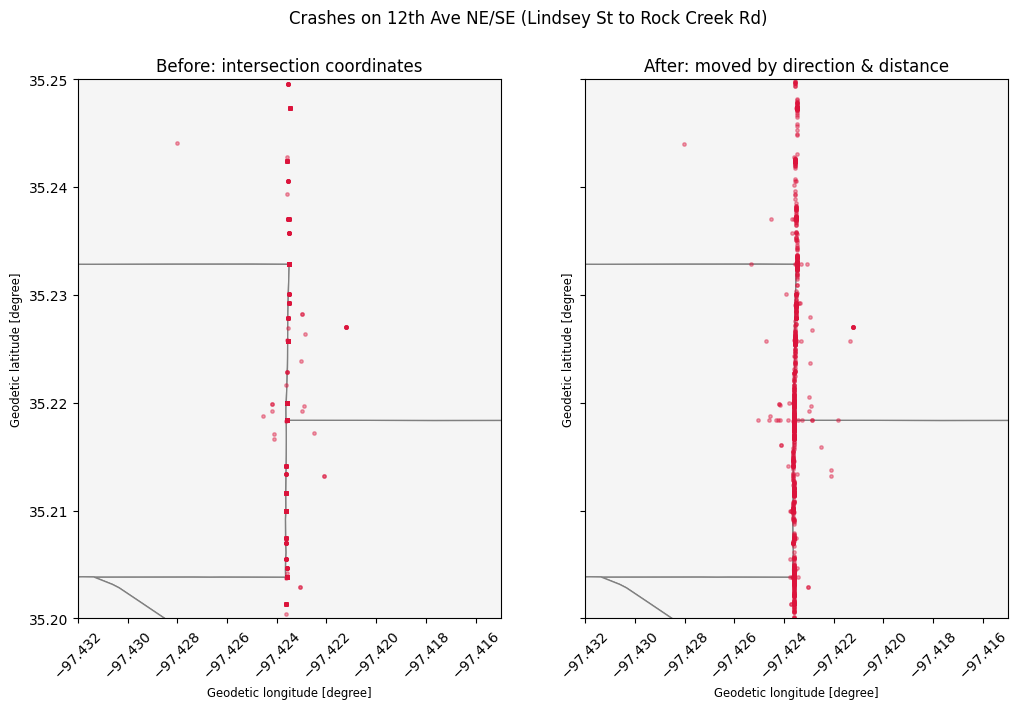

In [ ]:
on_12th = crashes[(crashes['StreetName'] == '12TH') & crashes['StreetSuffix'].isin(['NE', 'SE'])]

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
for ax, lat_col, lon_col, title in [(axes[0], 'Lat', 'Lon', 'Before: intersection coordinates'),
                                    (axes[1], 'crash_lat', 'crash_lon', 'After: moved by direction & distance')]:
    wards.plot(ax=ax, color='whitesmoke', edgecolor='grey')
    ax.scatter(on_12th[lon_col], on_12th[lat_col], s=6, color='crimson', alpha=0.4)
    ax.set_xlim(-97.432, -97.415)       # zoom in: 12th Ave between Lindsey St and Rock Creek Rd
    ax.set_ylim(35.200, 35.250)
    ax.set_aspect('auto')               # stretch the narrow strip so we can see it
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_title(title)
plt.suptitle('Crashes on 12th Ave NE/SE (Lindsey St to Rock Creek Rd)')
plt.show()

---
## B8. Save your work
Save the crashes with the new columns, so the next lab can start from here. (We keep only the useful columns.)

In [ ]:
keep = ['AccidentNumber', 'AccidentDatetime', 'StreetName', 'StreetType', 'StreetSuffix', 'XStreetName',
        'From_At', 'Direction', 'Distance', 'Lat', 'Lon', 'crash_lat', 'crash_lon', 'private', 'CauseCode']
crashes[keep].to_csv(DATA_FOLDER + 'collisions_with_locations.csv', index=False)
print('Saved', len(crashes), 'rows to', DATA_FOLDER + 'collisions_with_locations.csv')

Saved 23595 rows to /content/drive/MyDrive/Colab Notebooks/MIS3213/Norman_Traffic_Analysis/data/collisions_with_locations.csv


---
## Summary

| Step | What we did | Python skills |
|---|---|---|
| A | Loaded the ward GeoJSON, looked at its CRS, drew it, found the ward of a point | `gpd.read_file`, `.plot()`, `for` loop, `.contains()` |
| B1–B2 | Loaded `Base_Data` and read the location columns like a sentence | `pd.read_excel`, `value_counts` |
| B3 | Turned -361 into missing values | `.loc`, `np.nan` |
| B4 | Built an intersection phone book from `At` crashes | functions, `sorted`, `groupby`, dictionary |
| B5 | Filled missing coordinates using the phone book | `split`, `.get()`, `iterrows` |
| B6 | Moved `From` crashes by direction and distance | `if/elif`, `math.cos` |
| B7 | Checked the result with numbers and a map | `scatter` plots |

